In [2]:
from ior2ecl import runsim
from pathlib import Path

home = Path.home()
shared = Path('/home/shared/owner')
cop = shared/'CoP_files'

#root = cop/'output/K-9A_PROD/K-9A_PROD'
root = cop/'input/K-9A_PROD/K-9A_PROD'
#root = cop/'input/K-9A_PROD/K-9A_PROD_restart_364_0'
iorexe = home/'github/IORSim/build/bin/IORSimX'

# IX
runsim(root=root, iorexe=iorexe, nproc=20, nice=19, only_host=True, intersect=1);
# IX + IORSim in tandem
#runsim(root=root, iorexe=iorexe, nproc=20, nice=19, intersect=1, tandem=1, verbose=2);
# IORSim 
#runsim(root=root, iorexe=iorexe, only_iorsim=True, intersect=1, tandem=1, del_tandem=True);
#runsim(root=root, iorexe=iorexe, only_iorsim=True, intersect=1);


    Case      : K-9A_PROD
    Mode      : Intersect
    Days      : 699.0
    Run-dir   : /home/AD.NORCERESEARCH.NO/javi/github/IORSim_GUI
    Case-dir  : /home/shared/owner/CoP_files/input/K-9A_PROD
    Log-files : /home/shared/owner/CoP_files/input/K-9A_PROD/intersect.log
              : /home/shared/owner/CoP_files/input/K-9A_PROD/ior2ecl.log
    Version   : 3.7.3
    Started   : 2025-02-18 14:06:37


   Simulation complete, run-time was 0:02:58                                             



In [3]:
from itertools import product
from re import A
from IORlib.ECL import EGRID_file, INIT_file, UNRST_file
from numpy import array
import matplotlib.pyplot as pl

egrid = EGRID_file(root)
i, j, k = (1, 50), (50, 51), (1, 23)
dim = [b-a for a, b in (i, j, k)]
ijk = product(*[range(*x) for x in (i, j, k)])
corners = list(egrid.cell_corners(ijk))
#x, y, z = zip(*egrid.cell_corners(ijk))
#X, Y, Z = [array(v).reshape(dim).squeeze() for v in (x, y, z)]
#X.shape
#unrst = UNRST_file(root)
#celldata = next(unrst.cellarray('CL'))
#pl.pcolormesh(X, Z, celldata.CL[slice(*i), slice(*j), slice(*k)].squeeze())


#celldata.CL[50:100, 50, :].shape
#X, Y, Z = [array(v).reshape(len(i), len(j), len(k), 4).squeeze() for v in (x, y, z)]
#X, Y, Z = [array(v).reshape(len(i), len(j), len(k), 4).squeeze() for v in (x, y, z)]
#X = array(x[0]).reshape(50, 23)
#Y = array(y).reshape(50, 23, -1)
#Z = array(z).reshape(50, 23, -1)
#array(x).shape

In [4]:
import pyvista as pv
import numpy as np
from pyvista import CellType
from itertools import batched, repeat

from IORlib.utils import flatten


cells = np.array(list(flatten((a, *b) for a,b in zip(repeat(4), batched(range(len(corners)*4), 4)))))
cell_type = CellType.QUAD*np.ones(len(corners), dtype=int)
points = np.array(corners).reshape(-1, 3)

grid = pv.UnstructuredGrid(cells, cell_type, points)
_ = grid.plot(show_edges=True, show_grid=True)



: 

In [12]:
cell1 = np.array(
    [
        [0, 0],
        [1, 0],
        [1, 1],
        [0, 1],
    ],
)

cell2 = np.array(
    [
        [0, 2],
        [1, 2],
        [1, 3],
        [0, 3],
    ],
)
points = np.vstack((cell1, cell2)).astype(float)
points.shape

(8, 2)

In [6]:
print(X[0,0])
print(X[0,1])
print(X[1,0])
print(X[1,1])
print()
print(Y[0,0])
print(Y[0,1])
print(Y[1,0])
print(Y[1,1])
print()
print(Z[0,0])
print(Z[0,1])
print(Z[1,0])
print(Z[1,1])

4.921259880065918
4.921259880065918
9.842519760131836
9.842519760131836

246.06298828125
246.06298828125
246.06298828125
246.06298828125

9523.0
9537.0
9523.0
9537.0


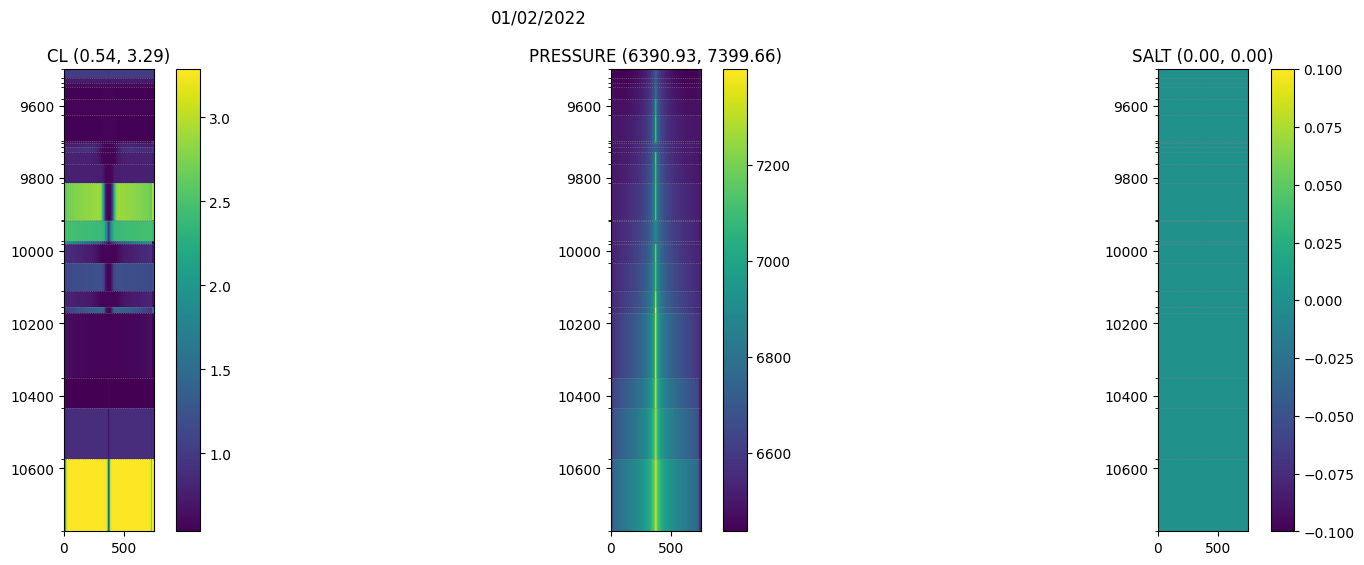

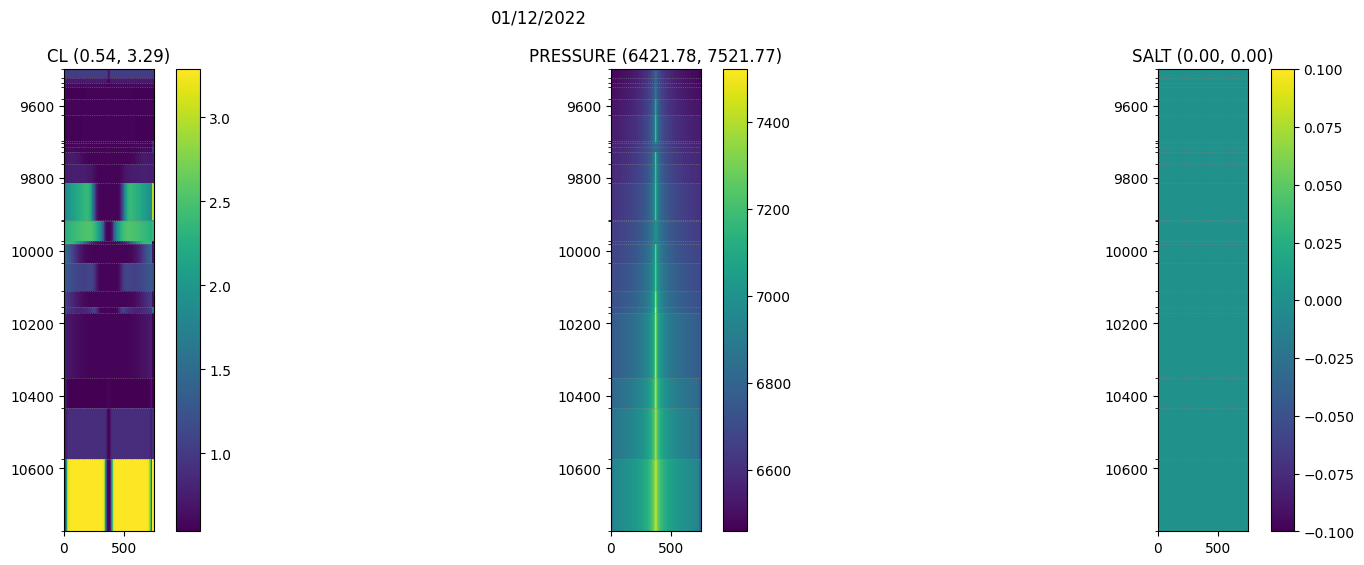

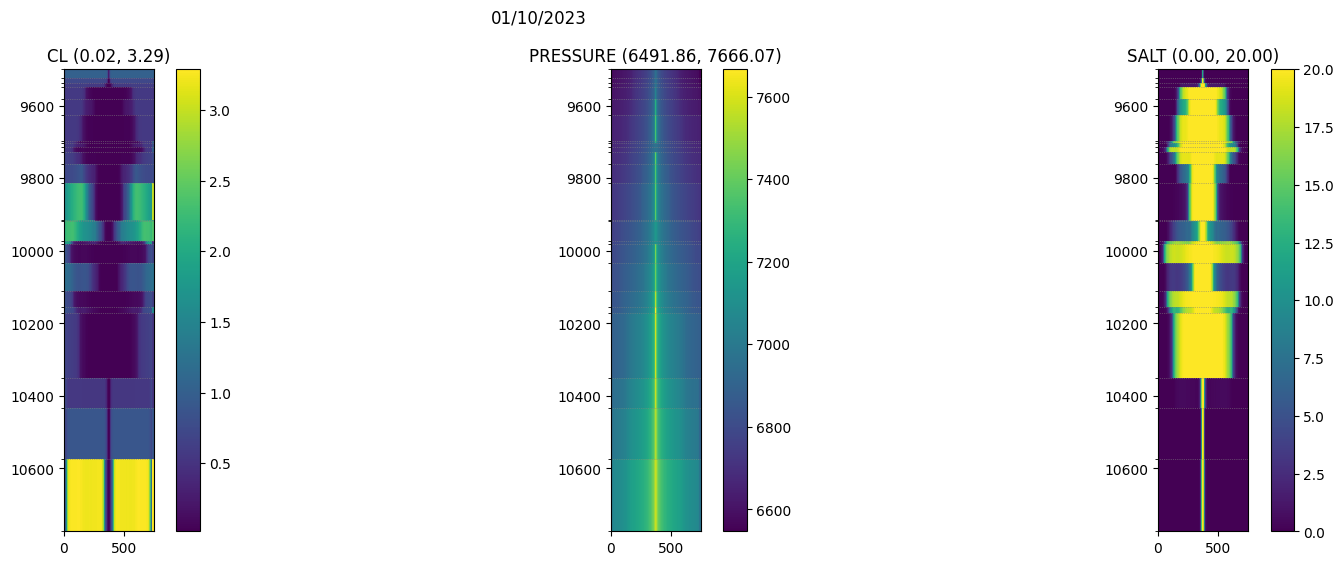

In [3]:
# Plot reservoir concentrations

import matplotlib.pyplot as pl
from numpy import rot90
from IORlib.ECL import UNRST_file, EGRID_file
from IORlib.utils import batched, take

%matplotlib inline

egrid = EGRID_file(root)
zpos = sorted(set(*egrid.blockdata('ZCORN')))
xpos = [v[0] for v in take(152, batched(*egrid.blockdata('COORD'), 6))]

unrst = UNRST_file(root)
#vars = ('CL', 'CA', 'MG', 'SO4')
vars = ('CL', 'PRESSURE', 'SALT')
for day, date, *data in unrst.cellarray(*vars, step=10, stop=None):
    fig, axes = pl.subplots(1, len(data), figsize=(20, 6))
    fig.suptitle(date.strftime('%d/%m/%Y'))
    for d, ax, var in zip(data, axes, vars):
        ax.set_title(f'{var} ({d.min():.2f}, {d.max():.2f})')
        im = ax.pcolormesh(xpos, zpos[::-1],  rot90(d[75,:,:]), shading='auto')
        fig.colorbar(im, ax=ax)
        ax.invert_yaxis()
        ax.set_aspect(3)
        ax.set_yticks(zpos, minor=True)
        ax.grid(True, which='minor')
        ax.grid(which='minor', linestyle=':', linewidth=0.5, color='gray', alpha=1) 


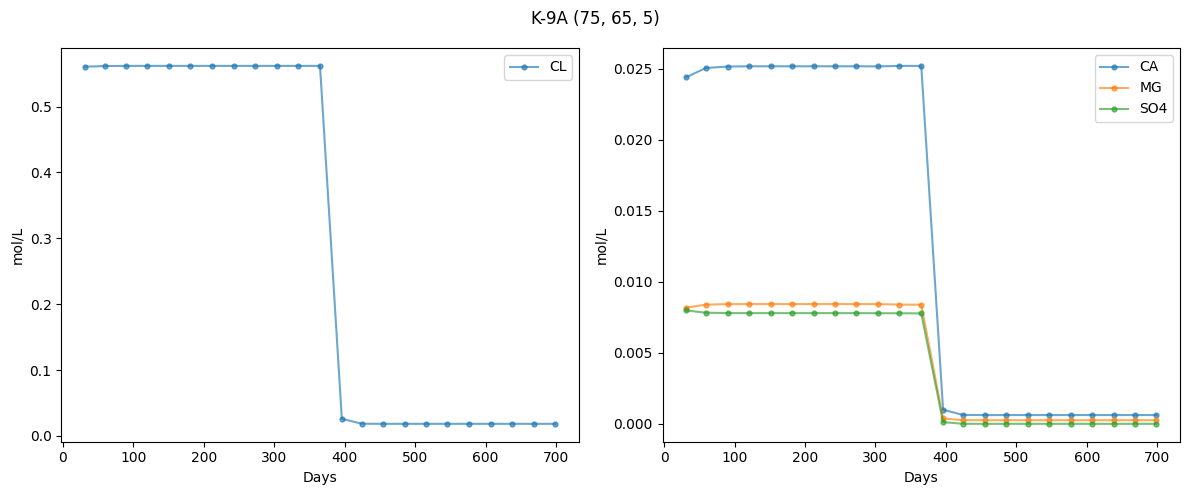

In [6]:

from pathlib import Path
from IORlib.ECL import UNRST_file
import matplotlib.pyplot as pl
from IORlib.utils import ensure_list, flatten

cell = (75, 65, 5)
vars = (['CL'], ['CA', 'MG', 'SO4'])
#fig, axes = pl.subplots(1, 1, figsize=(6, 5))
fig, axes = pl.subplots(1, len(vars), figsize=(6 * len(vars), 5))
fig.suptitle(f'K-9A {cell}')
#print(axes)
axes = ensure_list(axes)
unrst = UNRST_file(root)
days, dates, cl, *ca_mg_so4 = zip(*unrst.cellarray(*flatten(vars)))
data = [[cl], ca_mg_so4]
for ax, var, val in zip(axes, vars, data):
    for vname, dval in zip(var, val):
        #if vname == 'CL':
        #    ax.plot(days, [v[*cell] for v in dval], '-o', ms=3.5, label=f'{vname}', alpha=0.65)
        #else:
            # for n, d in zip(vname, dval):
        ax.plot(days, [v[*cell] for v in dval], '-o', ms=3.5, label=f'{vname}', alpha=0.65)    
#  print(vname, dval[:10])
#         ax.plot(days, [v[*cell] for v in dval], '-o', ms=3.5, label=f'{vname}', alpha=0.65)
    ax.legend()
    ax.set_xlabel('Days')
    ax.set_ylabel('mol/L')
pl.tight_layout()



/tmp/ipykernel_1346837/2087136322.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


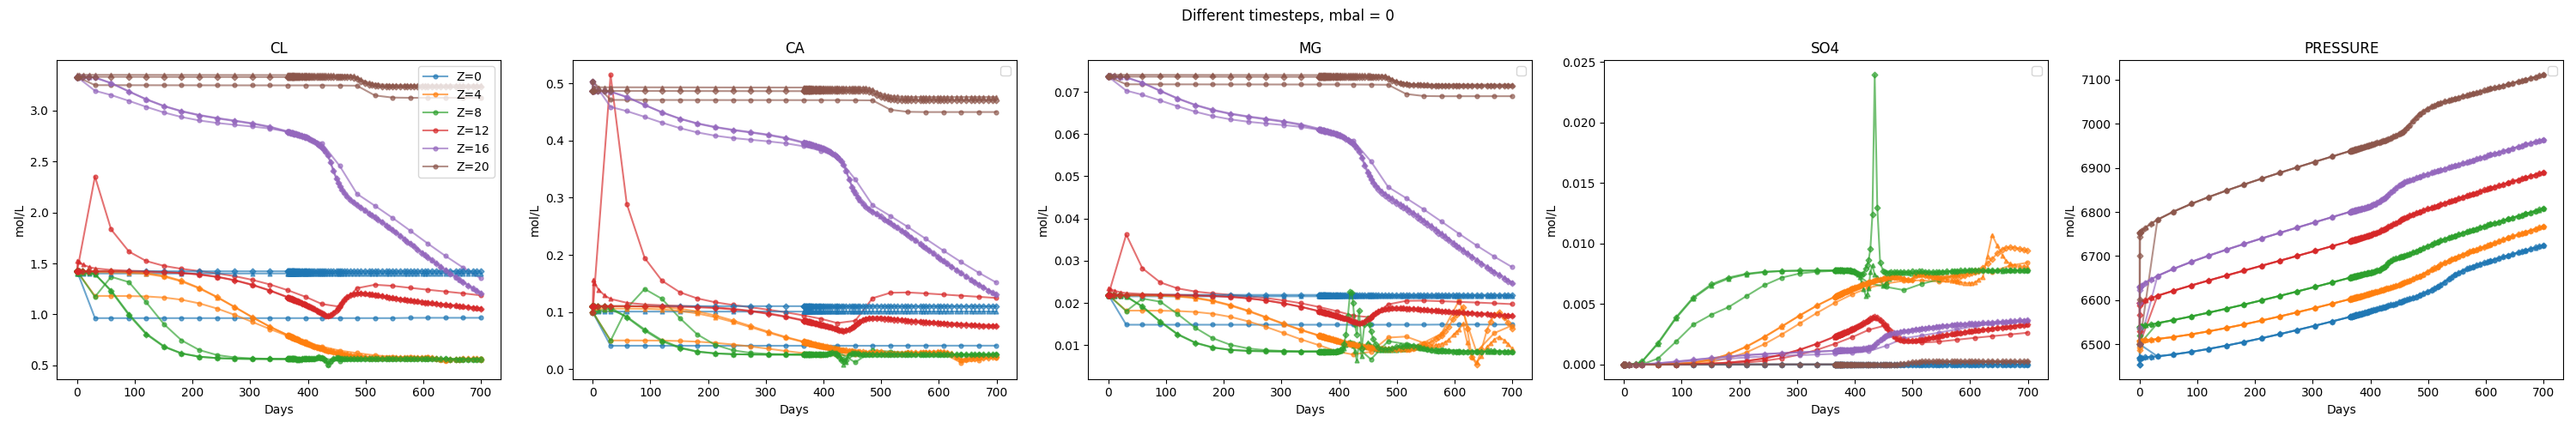

Saved /home/shared/owner/CoP_files/plots/all_runs_mbal0.pdf


/tmp/ipykernel_1346837/2087136322.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


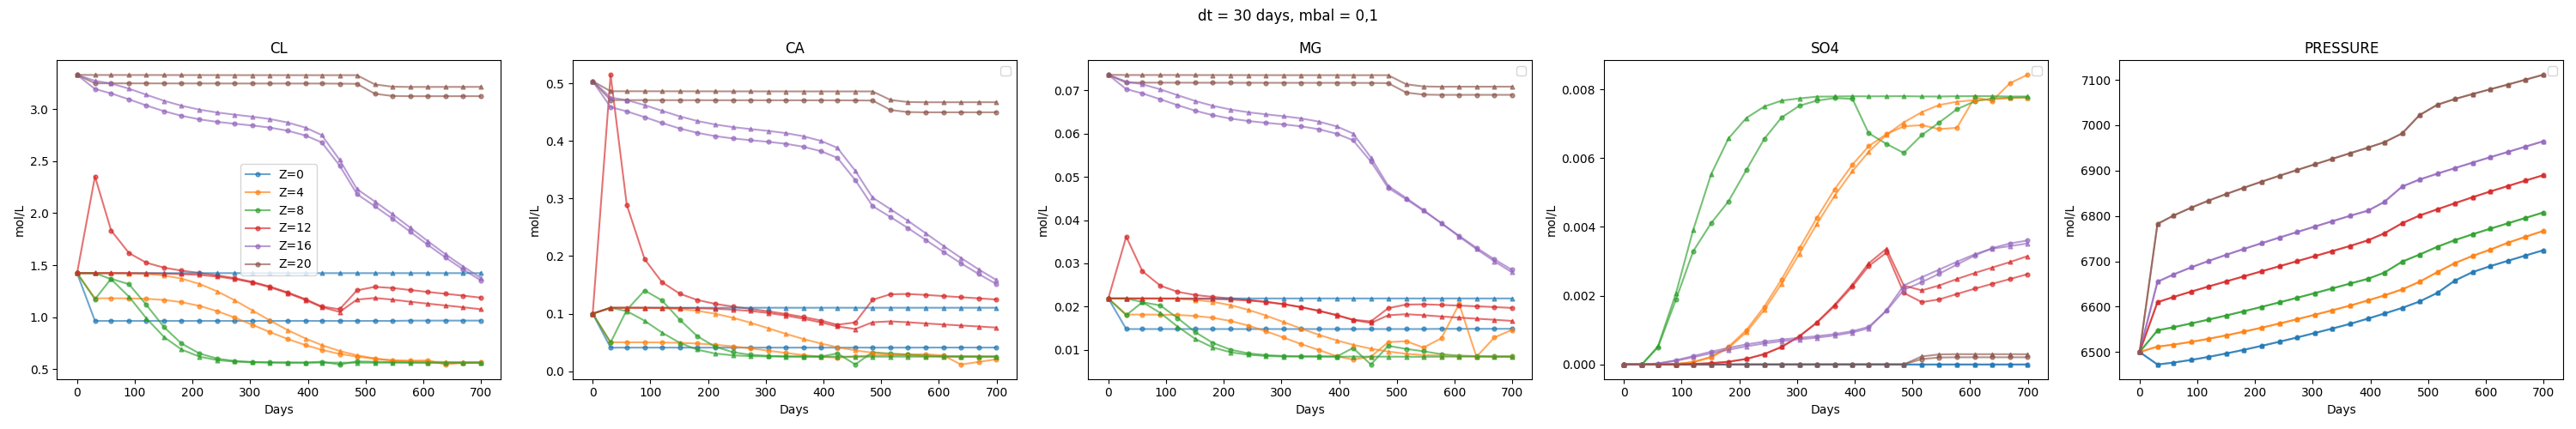

Saved /home/shared/owner/CoP_files/plots/dt30days_mbal01.pdf


/tmp/ipykernel_1346837/2087136322.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


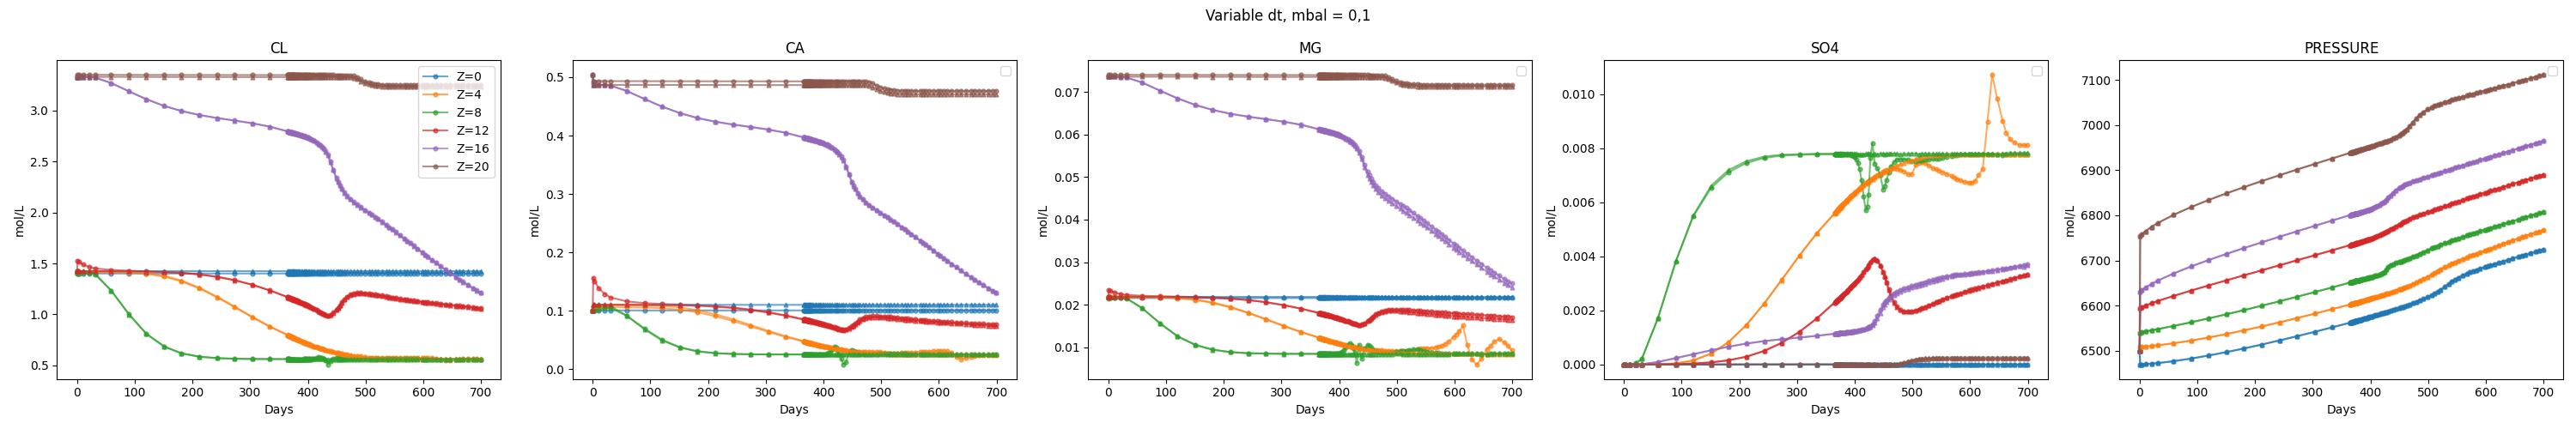

Saved /home/shared/owner/CoP_files/plots/var_dt_mbal01.pdf


/tmp/ipykernel_1346837/2087136322.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


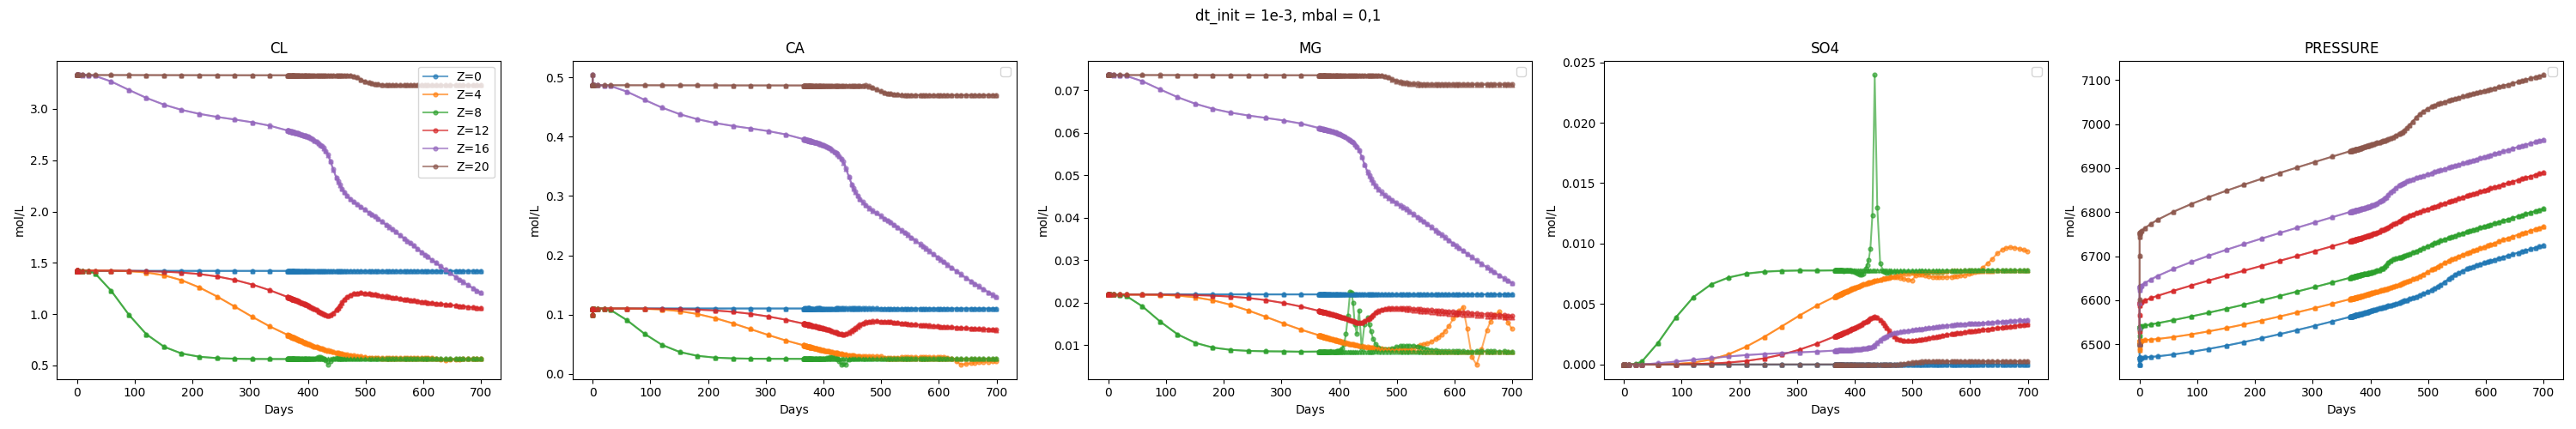

Saved /home/shared/owner/CoP_files/plots/dt_init_mbal01.pdf


/tmp/ipykernel_1346837/2087136322.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


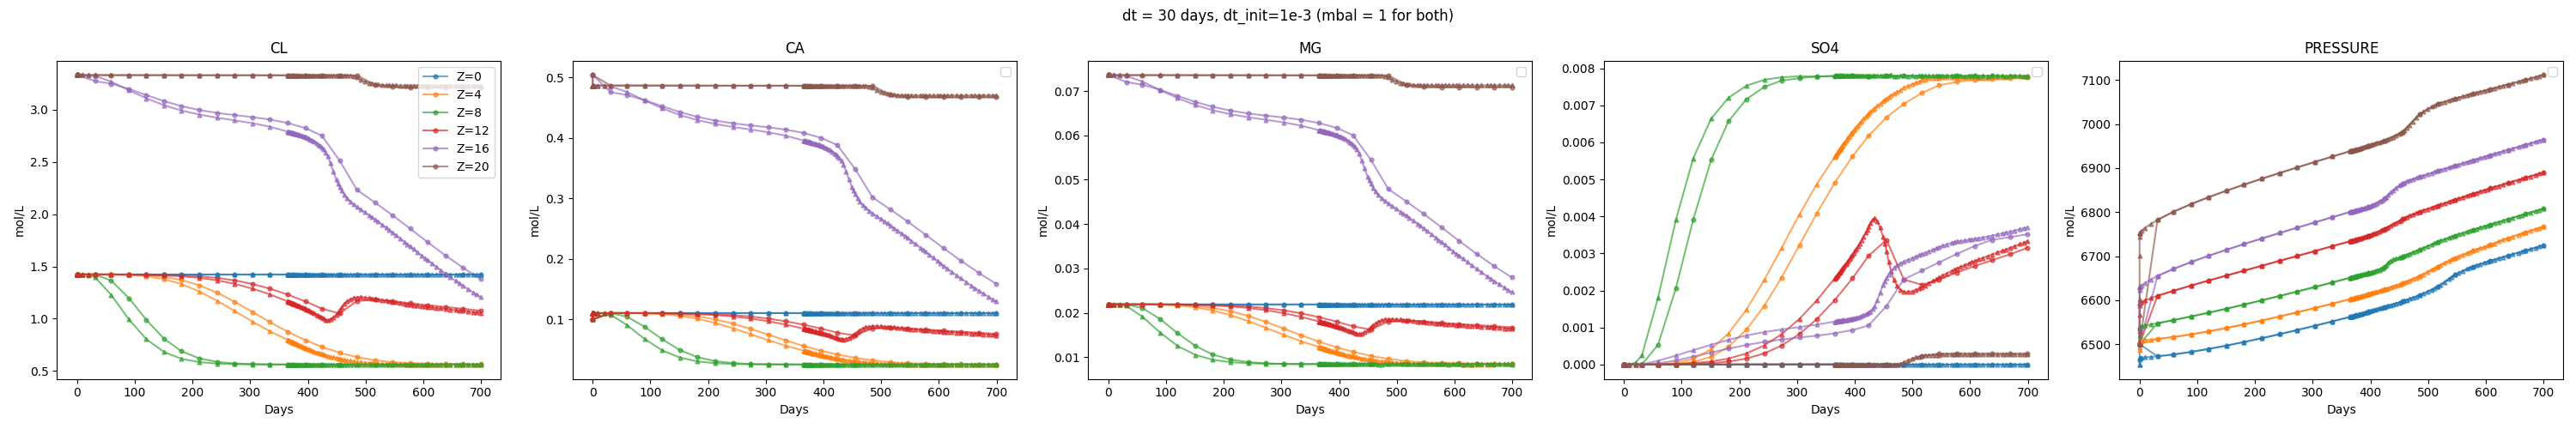

Saved /home/shared/owner/CoP_files/plots/dt_long_short_mbal1.pdf


In [9]:
# Compare chlorine for different runs

from pathlib import Path
from IORlib.ECL import UNRST_file
import matplotlib.pyplot as pl

from IORlib.utils import ensure_list

%matplotlib widget

def plot_runs(root, *paths, vars=(), cell=(75, 45), title=None):
    lines = ['-', '--', '-.', ':']
    markers = ['o', '^', 'D', 's', 'v', '<', '>', 'p', '*', 'h']
    colors = pl.rcParams['axes.prop_cycle'].by_key()['color']
    fig, axes = pl.subplots(1, len(vars), figsize=(6 * len(vars), 5))
    fig.suptitle(title)
    axes = ensure_list(axes)
    add_label = True
    for i, pth in enumerate(paths):
        unrst = UNRST_file(root.parent / pth / root.name)
        days, dates, *data = zip(*unrst.cellarray(*vars))
        for ax, var, val in zip(axes, vars, data):
            for j, z in enumerate(range(0, 24, 4)):
                ax.plot(days, [v[*cell, z] for v in val], marker=markers[i],
                        ms=3.5, color=colors[j%len(colors)], label=f'Z={z}' if add_label else None,
                        linestyle=lines[0], alpha=0.65)
            add_label = False
            ax.legend()
            ax.set_title(var)
            ax.set_xlabel('Days')
            ax.set_ylabel('mol/L')
    pl.tight_layout()
    pl.show()
    return fig

cop = Path('/home/shared/owner/CoP_files')
root = cop/'input/K-9A_PROD/K-9A_PROD'
paths = ['IORSIM_target_times_mbal0', 
         'IORSIM_target_times_mbal1',
         'IORSIM_converged_times_mbal0',
         'IORSIM_converged_times_mbal1',
         'IORSIM_converged_times_dtinit-1e-3_mbal0',
         'IORSIM_converged_times_dtinit-1e-3_mbal1']

pl.close('all')
vars = ['CL', 'CA', 'MG', 'SO4', 'PRESSURE']
plots = cop/'plots'

title = 'Different timesteps, mbal = 0'
fig = plot_runs(root, *paths[::2], vars=vars, title=title)
pdf = plots/'all_runs_mbal0.pdf'
pl.savefig(pdf)
print(f'Saved {pdf}')

title = 'dt = 30 days, mbal = 0,1'
plot_runs(root, *paths[:2], vars=vars, title=title)
pdf = plots/'dt30days_mbal01.pdf'
pl.savefig(pdf)
print(f'Saved {pdf}')

title = 'Variable dt, mbal = 0,1'
plot_runs(root, *paths[2:4], vars=vars, title=title)
pdf = plots/'var_dt_mbal01.pdf'
pl.savefig(pdf)
print(f'Saved {pdf}')

title = 'dt_init = 1e-3, mbal = 0,1'
plot_runs(root, *paths[4:], vars=vars, title=title)
pdf = plots/'dt_init_mbal01.pdf'
pl.savefig(pdf)
print(f'Saved {pdf}')

title = 'dt = 30 days, dt_init=1e-3 (mbal = 1 for both)'
plot_runs(root, paths[1], paths[5], vars=vars, title=title)
pdf = plots/'dt_long_short_mbal1.pdf'
pl.savefig(pdf)
print(f'Saved {pdf}')


In [6]:
import numpy as np
np.diff(zpos)

array([ 23.,  14.,  13.,  33.,  43.,  73.,   4.,  11.,  13.,  35.,  50.,
       102.,   4.,  54.,   9.,  53.,  78.,  44.,  15., 181.,  81., 140.,
       200.])

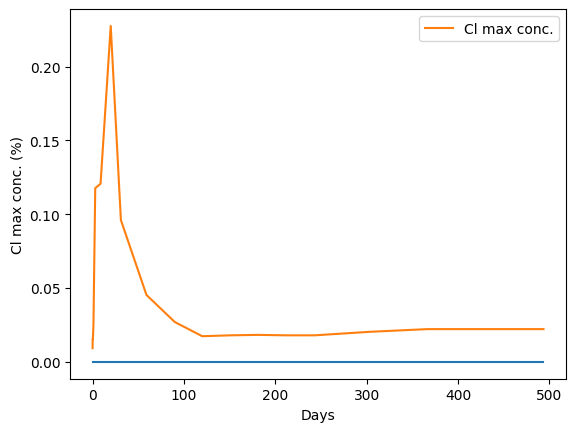

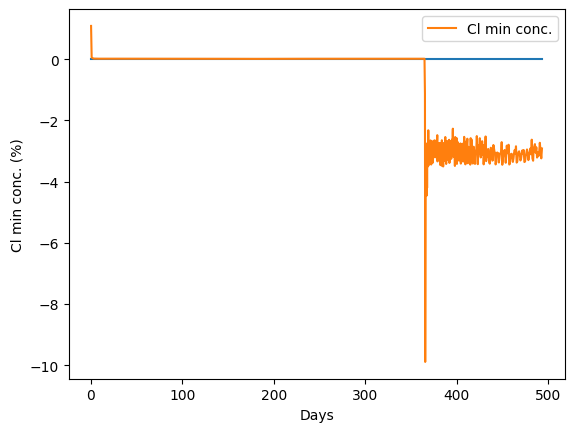

In [5]:
# Plotting Cl concentration max, min limits

import matplotlib.pyplot as pl
import numpy as np

cl_limits = np.genfromtxt(cop/'input/K-9A_PROD/K-9A_PROD_CL_limits_watsat.dat')
pl.figure()
days = cl_limits[::2,0]
pl.plot(days, np.zeros(len(days)))
pl.plot(days, 100*((cl_limits[::2,2]/cl_limits[::2,1])-1), label='Cl max conc.')
pl.legend()
pl.xlabel('Days')
pl.ylabel('Cl max conc. (%)')
pl.figure()
days = cl_limits[11::2,0]
pl.plot(days, np.zeros(len(days)))
pl.plot(days, 100*((cl_limits[11::2,2]/cl_limits[11::2,1])-1), label='Cl min conc.')
pl.xlabel('Days')
pl.ylabel('Cl min conc. (%)')
pl.legend()

In [ ]:
from IORlib.ECL import IX_input, UNSMRY_file

inp = IX_input(root, check=True)
print(inp.wells())
smry = UNSMRY_file(root)
print(smry.path)
wells = smry.welldata(named=True)
keys = wells._fields[2:]
print(keys)
smry.plot(('WWIR', 'WBHP', 'WSIC', 'WSPC'))
#wells.values


In [ ]:
from IORlib.ECL import IX_input

ix = IX_input(root)
ix.datesteps((2023,1,1), 0.25, 0.25/24)
ix.datesteps((2023,1,1,6,30), 0.75, 0.5/24)
ix.datesteps((2023,1,2,1), 1, 1/24)
ix.datesteps((2023,1,3,2), 1, 2/24)
ix.datesteps((2023,1,4,2), 1, 4/24)
ix.datesteps((2023,1,5,4), 1, 8/24)
ix.datesteps((2023,1,6), 1.5, 12/24)
ix.datesteps((2023,1,8), 2, 1)
ix.datesteps((2023,1,10), 6, 2)
ix.datesteps((2023,1,16), 12, 4)
